# Phase 5 — Recovery Validation and Safety

## Research Objective

Evaluate whether the automated recovery mechanism developed in Phase 4 preserves acceptable predictive performance after correcting feature-specific missingness.

The experiment will compare recovered validation batches against the healthy logistic regression baseline and implement explicit acceptance and rejection criteria.

## Research Questions

1. How does model performance change after applying median imputation to corrupted BILL_AMT1 values?
2. Does the recovery process preserve an acceptable F1-score relative to the healthy baseline?
3. How do recall and ROC-AUC change as injected missingness increases?
4. Can the SHML system automatically identify recovery outcomes that violate predefined safety criteria?

## Experimental Configuration

| Component | Configuration |
|---|---|
| Dataset | UCI Default of Credit Card Clients |
| Prediction task | Binary classification |
| Baseline model | Logistic Regression |
| Monitoring feature | BILL_AMT1 |
| Failure type | Numerical missingness |
| Recovery method | Training-derived median imputation |
| Missingness scenarios | 0%, 5%, 15%, 30% |
| Healthy F1-score | 0.3570 |
| Healthy recall | 0.2402 |
| Healthy ROC-AUC | 0.7130 |
| Maximum relative F1 loss | 10% |
| Minimum acceptable F1 | Approximately 0.3213 |
| Evaluation data | Held-out validation set |
| Final test set | Reserved |

## Research Hypothesis

As the proportion of missing BILL_AMT1 values increases, predictive performance may deteriorate despite successful median imputation.

A predefined recovery acceptance criterion can identify corrected batches that fail to preserve the required level of model performance.

## Evaluation Strategy

For each recovered batch:

1. Confirm that required features are present and contain no unsupported missing values.
2. Apply the StandardScaler fitted on the original training data.
3. Generate predictions using the unchanged healthy logistic regression model.
4. Calculate accuracy, precision, recall, F1-score, and ROC-AUC.
5. Compare performance against the healthy validation baseline.
6. Calculate relative F1 degradation.
7. Apply the predefined acceptance criteria.
8. Record the recovery decision and supporting metrics.

## Safety Principles

**No validation leakage:** The scaler and recovery statistics must be fitted using training data only.

**Model preservation:** The healthy baseline model must remain unchanged during recovery evaluation.

**No automatic retraining:** This experiment evaluates preprocessing-based recovery rather than model retraining.

**No automatic deployment:** A successful offline evaluation does not authorize production deployment.

**Explicit rejection:** Recovery outcomes that violate safety criteria must not be approved automatically.

**Test-set isolation:** The reserved test set will not be used to tune recovery decisions.

## Expected Research Contribution

Phase 5 will distinguish successful data-quality correction from successful predictive-performance recovery.

It will also establish a reproducible framework for evaluating recovery safety using explicit quantitative criteria.

## Next Activity

Reproduce the Phase 4 recovery pipeline and healthy model in the Phase 5 notebook, then evaluate recovered batches under identical conditions.

In [2]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

RANDOM_STATE = 42

print("Phase 5 libraries imported successfully.")


Phase 5 libraries imported successfully.


In [3]:

from pathlib import Path

data_dir = Path("data/working")
candidates = sorted(data_dir.glob("*credit*card*clients*.xls*"))
if not candidates:
    raise FileNotFoundError(f"No dataset file found under {data_dir}")

DATA_PATH = str(candidates[0])
df = pd.read_excel(DATA_PATH, header=1)
df.head()

target_column = "default payment next month"

X = df.drop(columns=["ID", target_column])
y = df[target_column]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values:", X.isna().sum().sum())


Feature shape: (30000, 23)
Target shape: (30000,)
Missing values: 0


In [ ]:

# Reproduce the original train/validation/test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (21000, 23)
Validation: (4500, 23)
Testing: (4500, 23)


In [ ]:
#Reproduce the healthy baseline model
scaler = StandardScaler()

X_trained_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

baseline_model.fit(X_trained_scaled, y_train)

y_val_pred = baseline_model.predict(X_val_scaled)
y_val_prob = baseline_model.predict_proba(X_val_scaled)[:, 1]
healthy_metrics = {
    "accuracy": accuracy_score(y_val, y_val_pred),
    "precision": precision_score(y_val, y_val_pred, zero_division=0),
    "recall": recall_score(y_val, y_val_pred, zero_division=0),
    "f1": f1_score(y_val, y_val_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_val, y_val_prob)
}

display(pd.DataFrame([healthy_metrics]).round(4))


,accuracy,precision,recall,f1,roc_auc
0,0.8087,0.6948,0.2402,0.357,0.713


In [ ]:
# Recreate the missingness scenarios
missingness_levels = [0.00, 0.05, 0.15, 0.30]
corrupted_batches = {}

for rate in missingness_levels:
    X_corrupted = X_val.copy(deep = True)
    n_missing = int(len(X_corrupted)*rate)
    rng = np.random.default_rng(RANDOM_STATE)
    
    missing_positions = rng.choice(
        len(X_corrupted),
        size=n_missing,
        replace=False
    )
    feature_idx = X_corrupted.columns.get_loc("BILL_AMT1")

    X_corrupted.iloc[missing_positions, feature_idx] = np.nan

    corrupted_batches[rate] = X_corrupted

    print(
        f"Missingness: {rate:.0%} | "
        f"Missing values: "
        f"{X_corrupted['BILL_AMT1'].isna().sum()}"
    )


Missingness: 0% | Missing values: 0
Missingness: 5% | Missing values: 225
Missingness: 15% | Missing values: 675
Missingness: 30% | Missing values: 1350


In [8]:
#Reproduce the Phase 4 recovery logic


bill_amt1_median = X_train["BILL_AMT1"].median()

recovered_batches = {}

for rate, X_corrupted in corrupted_batches.items():

    X_recovered = X_corrupted.copy(deep=True)

    X_recovered["BILL_AMT1"] = (
        X_recovered["BILL_AMT1"].fillna(bill_amt1_median)
    )

    recovered_batches[rate] = X_recovered

    print(
        f"Missingness: {rate:.0%} | "
        f"Remaining missing: "
        f"{X_recovered['BILL_AMT1'].isna().sum()}"
    )

print("Training median:", bill_amt1_median)


Missingness: 0% | Remaining missing: 0
Missingness: 5% | Remaining missing: 0
Missingness: 15% | Remaining missing: 0
Missingness: 30% | Remaining missing: 0
Training median: 22225.5


In [9]:
# Verify the experiment is ready

assert X_train.shape == (21000, 23)
assert X_val.shape == (4500, 23)
assert X_test.shape == (4500, 23)

assert abs(healthy_metrics["f1"] - 0.3570) < 0.0001

expected_missing = {
    0.00: 0,
    0.05: 225,
    0.15: 675,
    0.30: 1350
}

for rate in missingness_levels:

    X_corrupted = corrupted_batches[rate]
    X_recovered = recovered_batches[rate]

    assert (
        X_corrupted["BILL_AMT1"].isna().sum()
        == expected_missing[rate]
    )

    assert X_recovered.isna().sum().sum() == 0

    # Existing values must remain unchanged.
    observed = X_corrupted["BILL_AMT1"].notna()

    pd.testing.assert_series_equal(
        X_recovered.loc[observed, "BILL_AMT1"],
        X_corrupted.loc[observed, "BILL_AMT1"]
    )

    # Other features must remain unchanged.
    other_features = X_corrupted.columns.drop("BILL_AMT1")

    pd.testing.assert_frame_equal(
        X_recovered[other_features],
        X_corrupted[other_features]
    )

print("Phase 5.2 verification passed.")
print("Baseline and recovered batches are ready for evaluation.")


Phase 5.2 verification passed.
Baseline and recovered batches are ready for evaluation.


## Step 5.3 — Predictive Performance After Recovery

### Objective

Evaluate the predictive performance of the healthy logistic regression model on validation batches that have undergone training-median imputation.

### Experimental Design

Four validation batches will be evaluated, corresponding to 0%, 5%, 15%, and 30% injected missingness in BILL_AMT1.

Each batch will be processed using the StandardScaler fitted on the original training dataset and evaluated using the unchanged baseline logistic regression model.

### Evaluation Metrics

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of predicted defaults that are actual defaults.
- **Recall:** Proportion of actual defaults correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Ability of the model to rank positive examples above negative examples across classification thresholds.

### Expected Outcome

Median imputation should eliminate missing values, but predictive performance may change because replacing original values with the training median removes information.

The experiment will measure these changes rather than assuming that successful imputation guarantees successful recovery.

### Experimental Controls

The model, scaler, validation labels, feature order, and random seed remain consistent across all four scenarios.

The reserved test dataset will not be evaluated during this step.

In [10]:

# Phase 5.3 — Evaluate recovered validation batches

evaluation_results = []

for rate in missingness_levels:

    # Retrieve recovered validation batch
    X_recovered = recovered_batches[rate]

    # Apply the existing training-fitted scaler
    X_recovered_scaled = scaler.transform(X_recovered)

    # Predict using the unchanged healthy model
    y_pred = baseline_model.predict(X_recovered_scaled)
    y_prob = baseline_model.predict_proba(
        X_recovered_scaled
    )[:, 1]

    # Calculate performance metrics
    metrics = {
        "Missingness": rate,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    }

    evaluation_results.append(metrics)

# Create performance comparison table
performance_df = pd.DataFrame(evaluation_results)

print("Phase 5.3 — Performance After Recovery")
display(performance_df.round(4))


Phase 5.3 — Performance After Recovery


,Missingness,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.00,0.8087,0.6948,0.2402,0.3570,0.7130
1,0.05,0.8087,0.6925,0.2422,0.3589,0.7132
2,0.15,0.8080,0.6835,0.2452,0.3609,0.7090
3,0.30,0.8093,0.6827,0.2573,0.3737,0.7111


In [11]:

# Verify all four scenarios were evaluated
assert len(performance_df) == 4

# Verify no evaluation metric is missing
assert performance_df.isna().sum().sum() == 0

# Verify all metrics fall within [0, 1]
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

assert performance_df[metric_columns].ge(0).all().all()
assert performance_df[metric_columns].le(1).all().all()

# Verify healthy scenario matches original baseline
healthy_row = performance_df.loc[
    performance_df["Missingness"] == 0.0
].iloc[0]

assert np.isclose(
    healthy_row["F1"],
    healthy_metrics["f1"],
    atol=1e-10
)

assert np.isclose(
    healthy_row["Recall"],
    healthy_metrics["recall"],
    atol=1e-10
)

assert np.isclose(
    healthy_row["ROC-AUC"],
    healthy_metrics["roc_auc"],
    atol=1e-10
)

print("Phase 5.3 verification passed.")
print("All recovered batches evaluated successfully.")


Phase 5.3 verification passed.
All recovered batches evaluated successfully.


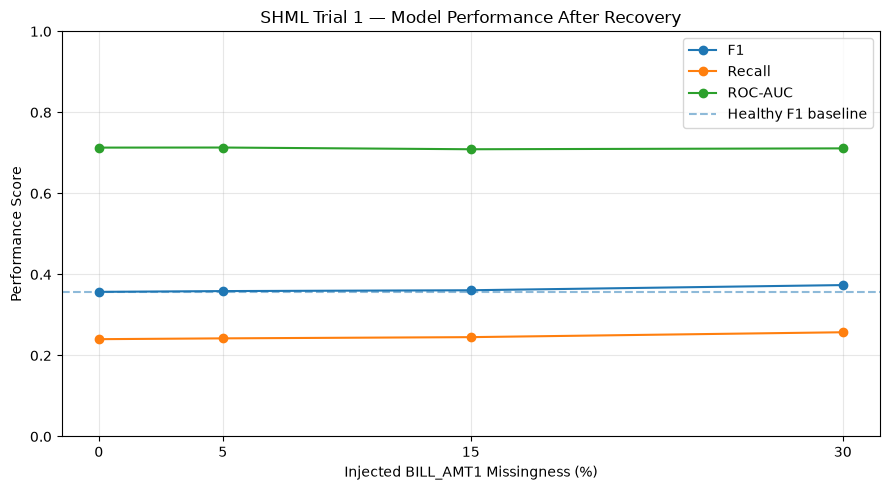

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ["F1", "Recall", "ROC-AUC"]:
    plt.plot(
        performance_df["Missingness"] * 100,
        performance_df[metric],
        marker="o",
        label=metric
    )

plt.axhline(
    y=healthy_metrics["f1"],
    linestyle="--",
    alpha=0.5,
    label="Healthy F1 baseline"
)

plt.xlabel("Injected BILL_AMT1 Missingness (%)")
plt.ylabel("Performance Score")
plt.title("SHML Trial 1 — Model Performance After Recovery")
plt.xticks([0, 5, 15, 30])
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

from pathlib import Path

output_dir = Path("results/phase5")
output_dir.mkdir(parents=True, exist_ok=True)

performance_df.to_csv(
    output_dir / "phase5_recovery_performance.csv",
    index=False
)

print("Phase 5.3 performance results saved successfully.")


Phase 5.3 performance results saved successfully.


In [14]:

print("Phase 5.3 — Exact Performance Results")
display(performance_df.round(6))


Phase 5.3 — Exact Performance Results


,Missingness,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.00,0.808667,0.694767,0.240201,0.356983,0.713025
1,0.05,0.808667,0.692529,0.242211,0.358898,0.713210
2,0.15,0.808000,0.683473,0.245226,0.360947,0.708958
3,0.30,0.809333,0.682667,0.257286,0.373723,0.711135



## Step 5.4 — Calculate Performance Degradation

### Objective

Measure how much the F1-score changes after applying median imputation to each corrupted validation batch, compared with the healthy baseline model.

### Relative F1 Loss

The relative F1 loss is calculated as:

$$
\text{Relative F1 Loss (\%)} =
\frac{F1_{\text{healthy}} - F1_{\text{recovered}}}
{F1_{\text{healthy}}}
\times 100
$$

Where:

- **Healthy F1:** F1-score obtained using the original validation dataset.
- **Recovered F1:** F1-score obtained after correcting the missing values.
- **Relative F1 Loss:** Percentage change in performance relative to the healthy baseline.

### Acceptance Criterion

The maximum acceptable relative F1 loss is **10%**.

$$
F1_{\text{minimum}} =
F1_{\text{healthy}} \times (1 - 0.10)
$$

Using the healthy baseline:

$$
F1_{\text{minimum}} =
0.356983 \times 0.90
\approx 0.321285
$$

### Interpretation

- **Positive relative F1 loss:** Performance decreased after recovery.
- **Zero relative F1 loss:** Performance remained unchanged.
- **Negative relative F1 loss:** Recovered F1-score exceeded the healthy baseline.

A recovered batch meets the initial F1 acceptance criterion when its relative F1 loss is less than or equal to 10%.

Meeting this criterion does not automatically establish that the recovered batch is safe for deployment. Additional performance and data-integrity checks are required.


In [15]:

# Step 5.4 — Calculate relative performance changes

healthy_f1 = healthy_metrics["f1"]
healthy_recall = healthy_metrics["recall"]
healthy_auc = healthy_metrics["roc_auc"]

MAX_F1_LOSS = 0.10
minimum_acceptable_f1 = healthy_f1 * (1 - MAX_F1_LOSS)

degradation_df = performance_df.copy()

degradation_df["F1 Relative Loss (%)"] = (
    (healthy_f1 - degradation_df["F1"])
    / healthy_f1
) * 100

degradation_df["Recall Change (pp)"] = (
    degradation_df["Recall"] - healthy_recall
) * 100

degradation_df["ROC-AUC Change"] = (
    degradation_df["ROC-AUC"] - healthy_auc
)

degradation_df["F1 Criterion Met"] = (
    degradation_df["F1"] >= minimum_acceptable_f1
)

print("Minimum acceptable F1:", round(minimum_acceptable_f1, 6))

display(
    degradation_df[
        [
            "Missingness",
            "F1",
            "F1 Relative Loss (%)",
            "Recall Change (pp)",
            "ROC-AUC Change",
            "F1 Criterion Met"
        ]
    ].round(6)
)


Minimum acceptable F1: 0.321285


,Missingness,F1,F1 Relative Loss (%),Recall Change (pp),ROC-AUC Change,F1 Criterion Met
0,0.00,0.356983,0.000000,0.000000,0.000000,True
1,0.05,0.358898,-0.536487,0.201005,0.000185,True
2,0.15,0.360947,-1.110396,0.502513,-0.004067,True
3,0.30,0.373723,-4.689247,1.708543,-0.001890,True


### Phase 5.4 — Preliminary Research Findings

The recovered validation batches maintained F1-scores at or above the healthy baseline across all tested BILL_AMT1 missingness scenarios.

At 30% injected missingness, the recovered F1-score increased from approximately 0.3570 to 0.3737, while precision decreased and recall increased.

ROC-AUC remained relatively stable, although the 15% scenario showed a small decrease.

All tested scenarios satisfied the predefined maximum relative F1-loss tolerance of 10%.

These findings suggest that training-median imputation preserved the selected model's F1-score under the tested feature-specific corruption conditions.

However, successful data correction and acceptable F1-score do not independently establish that recovery is safe for deployment.

The experiment used one validation split, one random seed, one feature, and one recovery strategy. Additional safety checks and repeated experiments are necessary before making broader reliability claims.


## Step 5.5 — Recovery Acceptance and Rejection Engine

### Objective

Develop a rule-based safety decision engine that evaluates
whether recovered validation batches satisfy predefined
data-integrity and predictive-performance requirements.

### Safety Criteria

A recovered batch is accepted only when:

1. All required features are present.
2. No missing values remain.
3. Relative F1 loss is at most 10%.
4. Relative recall loss is at most 10%.
5. Evaluation metrics are valid.

ROC-AUC will be monitored but will not determine acceptance
in this initial experiment.

### Decision Logic

- ACCEPT: All required safety checks pass.
- REJECT: At least one required safety check fails.

These decisions apply to offline experimental validation.
They do not constitute production deployment approval.


In [16]:

def evaluate_recovery_safety(
    recovered_metrics,
    healthy_metrics,
    data_integrity_passed,
    max_f1_loss=0.10,
    max_recall_loss=0.10
):
    """
    Evaluate offline recovery acceptance criteria.
    """

    required_metrics = [
        "accuracy", "precision", "recall", "f1", "roc_auc"
    ]

    metrics_valid = all(
        metric in recovered_metrics
        and np.isfinite(recovered_metrics[metric])
        and 0 <= recovered_metrics[metric] <= 1
        for metric in required_metrics
    )

    baseline_valid = (
        healthy_metrics["f1"] > 0
        and healthy_metrics["recall"] > 0
    )

    if not metrics_valid or not baseline_valid:
        return {
            "decision": "REJECT",
            "reason": "Invalid evaluation metrics or baseline",
            "f1_loss_pct": np.nan,
            "recall_loss_pct": np.nan
        }

    f1_loss = (
        healthy_metrics["f1"] - recovered_metrics["f1"]
    ) / healthy_metrics["f1"]

    recall_loss = (
        healthy_metrics["recall"] - recovered_metrics["recall"]
    ) / healthy_metrics["recall"]

    reasons = []

    if not data_integrity_passed:
        reasons.append("Data integrity check failed")

    if f1_loss > max_f1_loss:
        reasons.append("F1 loss exceeds tolerance")

    if recall_loss > max_recall_loss:
        reasons.append("Recall loss exceeds tolerance")

    decision = "REJECT" if reasons else "ACCEPT"

    return {
        "decision": decision,
        "reason": "; ".join(reasons) if reasons else "All checks passed",
        "f1_loss_pct": f1_loss * 100,
        "recall_loss_pct": recall_loss * 100
    }

print("Recovery safety decision function created.")


Recovery safety decision function created.


In [17]:

safety_results = []

for _, row in performance_df.iterrows():

    rate = float(row["Missingness"])
    X_recovered = recovered_batches[rate]

    # Check schema and remaining missing values
    integrity_passed = (
        X_recovered.columns.equals(X_train.columns)
        and X_recovered.isna().sum().sum() == 0
        and len(X_recovered) == len(X_val)
        and X_recovered.index.equals(X_val.index)
    )

    recovered_metrics = {
        "accuracy": row["Accuracy"],
        "precision": row["Precision"],
        "recall": row["Recall"],
        "f1": row["F1"],
        "roc_auc": row["ROC-AUC"]
    }

    result = evaluate_recovery_safety(
        recovered_metrics=recovered_metrics,
        healthy_metrics=healthy_metrics,
        data_integrity_passed=integrity_passed
    )

    safety_results.append({
        "Missingness": rate,
        "Data Integrity": integrity_passed,
        "F1": row["F1"],
        "Recall": row["Recall"],
        "ROC-AUC": row["ROC-AUC"],
        "F1 Loss (%)": result["f1_loss_pct"],
        "Recall Loss (%)": result["recall_loss_pct"],
        "Decision": result["decision"],
        "Reason": result["reason"]
    })

safety_df = pd.DataFrame(safety_results)

print("Phase 5.5 — Recovery Safety Decisions")
display(safety_df.round(4))


Phase 5.5 — Recovery Safety Decisions


,Missingness,Data Integrity,F1,Recall,ROC-AUC,F1 Loss (%),Recall Loss (%),Decision,Reason
0,0.00,True,0.3570,0.2402,0.7130,0.0000,0.0000,ACCEPT,All checks passed
1,0.05,True,0.3589,0.2422,0.7132,-0.5365,-0.8368,ACCEPT,All checks passed
2,0.15,True,0.3609,0.2452,0.7090,-1.1104,-2.0921,ACCEPT,All checks passed
3,0.30,True,0.3737,0.2573,0.7111,-4.6892,-7.1130,ACCEPT,All checks passed


In [18]:

# Simulated unsafe recovery result
unsafe_metrics = {
    "accuracy": 0.75,
    "precision": 0.40,
    "recall": 0.10,
    "f1": 0.16,
    "roc_auc": 0.60
}

unsafe_result = evaluate_recovery_safety(
    recovered_metrics=unsafe_metrics,
    healthy_metrics=healthy_metrics,
    data_integrity_passed=True
)

print("Simulated unsafe recovery:")
print(unsafe_result)

assert unsafe_result["decision"] == "REJECT"

print("Safety rejection test passed.")


Simulated unsafe recovery:
{'decision': 'REJECT', 'reason': 'F1 loss exceeds tolerance; Recall loss exceeds tolerance', 'f1_loss_pct': 55.179916317991626, 'recall_loss_pct': 58.36820083682008}
Safety rejection test passed.


In [19]:

from pathlib import Path

output_dir = Path("results/phase5")
output_dir.mkdir(parents=True, exist_ok=True)

safety_df.to_csv(
    output_dir / "phase5_safety_decisions.csv",
    index=False
)

print("Phase 5.5 safety decisions saved successfully.")


Phase 5.5 safety decisions saved successfully.



## Step 5.6 — Safe Fallback and Rollback Decision Logic

### Objective

Develop a rule-based fallback controller that determines the
next action after the recovery safety engine accepts or rejects
a corrected validation batch.

### Research Question

Can the SHML system automatically prevent rejected recovery
results from being approved and select a predefined fallback action?

### Decision Policy

**ACCEPT**

- Approve the recovered batch for further offline evaluation.
- Record the acceptance decision.
- Preserve the current healthy model and preprocessing configuration.

**REJECT**

- Block the recovered batch from automatic approval.
- Preserve the last approved model and preprocessing configuration.
- Escalate the rejected batch for investigation or manual review.
- Do not assume that reverting the model makes corrupted input safe.

### Fallback and Rollback

Fallback refers to selecting a predefined alternative action
when recovery is unsuccessful.

Rollback refers to restoring a previously approved model or
processing configuration.

Because the current SHML experiment is offline, Phase 5
implements fallback and rollback decision logic only.

Actual model restoration, deployment controls, and production
rollback will be implemented in a later integration phase.

### Safety Principle

A recovery operation must not be approved solely because
missing values were successfully corrected.

Approval requires successful data-integrity and
predictive-performance validation.


In [20]:

def select_fallback_action(
    safety_decision,
    safe_fallback_available=False
):
    """
    Select the next action after offline recovery validation.

    This function does not deploy or restore a model.
    It only records the intended control decision.
    """

    if safety_decision == "ACCEPT":
        return {
            "action": "APPROVE_FOR_OFFLINE_EVALUATION",
            "block_recovered_batch": False,
            "rollback_required": False,
            "manual_review_required": False,
            "explanation": (
                "Recovery satisfied the offline safety criteria."
            )
        }

    elif safety_decision == "REJECT":

        if safe_fallback_available:
            return {
                "action": "USE_APPROVED_FALLBACK",
                "block_recovered_batch": True,
                "rollback_required": False,
                "manual_review_required": False,
                "explanation": (
                    "Recovery rejected. Route to an independently "
                    "validated fallback."
                )
            }

        return {
            "action": "BLOCK_AND_ESCALATE",
            "block_recovered_batch": True,
            "rollback_required": False,
            "manual_review_required": True,
            "explanation": (
                "Recovery rejected. No validated fallback is "
                "available; automated prediction is blocked."
            )
        }

    raise ValueError(
        "Safety decision must be ACCEPT or REJECT."
    )


print("Fallback controller created successfully.")


Fallback controller created successfully.


In [21]:

fallback_results = []

for _, row in safety_df.iterrows():

    fallback = select_fallback_action(
        safety_decision=row["Decision"],
        safe_fallback_available=False
    )

    fallback_results.append({
        "Missingness": row["Missingness"],
        "Safety Decision": row["Decision"],
        "Fallback Action": fallback["action"],
        "Batch Blocked": fallback["block_recovered_batch"],
        "Rollback Required": fallback["rollback_required"],
        "Manual Review": fallback["manual_review_required"],
        "Explanation": fallback["explanation"]
    })

fallback_df = pd.DataFrame(fallback_results)

print("Phase 5.6 — Fallback Decisions")
display(fallback_df)


Phase 5.6 — Fallback Decisions


,Missingness,Safety Decision,Fallback Action,Batch Blocked,Rollback Required,Manual Review,Explanation
0,0.00,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False,False,Recovery satisfied the offline safety criteria.
1,0.05,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False,False,Recovery satisfied the offline safety criteria.
2,0.15,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False,False,Recovery satisfied the offline safety criteria.
3,0.30,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False,False,Recovery satisfied the offline safety criteria.


In [22]:

# Test A — Accepted recovery
test_accept = select_fallback_action(
    safety_decision="ACCEPT"
)

assert (
    test_accept["action"]
    == "APPROVE_FOR_OFFLINE_EVALUATION"
)

assert test_accept["block_recovered_batch"] is False


# Test B — Rejected recovery, no safe fallback
test_reject = select_fallback_action(
    safety_decision="REJECT",
    safe_fallback_available=False
)

assert test_reject["action"] == "BLOCK_AND_ESCALATE"
assert test_reject["block_recovered_batch"] is True
assert test_reject["manual_review_required"] is True


# Test C — Rejected recovery, validated fallback available
# Hypothetical control-flow test only
test_fallback = select_fallback_action(
    safety_decision="REJECT",
    safe_fallback_available=True
)

assert test_fallback["action"] == "USE_APPROVED_FALLBACK"
assert test_fallback["block_recovered_batch"] is True


# Test D — Invalid safety decision
try:
    select_fallback_action("UNKNOWN")
    raise AssertionError("Invalid decision was not rejected")
except ValueError:
    pass

print("All Phase 5.6 fallback controller tests passed.")


All Phase 5.6 fallback controller tests passed.


In [23]:

# Reuse the simulated unsafe result from Step 5.5
unsafe_metrics = {
    "accuracy": 0.75,
    "precision": 0.40,
    "recall": 0.10,
    "f1": 0.16,
    "roc_auc": 0.60
}

unsafe_safety = evaluate_recovery_safety(
    recovered_metrics=unsafe_metrics,
    healthy_metrics=healthy_metrics,
    data_integrity_passed=True
)

unsafe_fallback = select_fallback_action(
    safety_decision=unsafe_safety["decision"],
    safe_fallback_available=False
)

print("Safety decision:", unsafe_safety["decision"])
print("Safety reason:", unsafe_safety["reason"])
print("Fallback action:", unsafe_fallback["action"])

assert unsafe_safety["decision"] == "REJECT"
assert unsafe_fallback["action"] == "BLOCK_AND_ESCALATE"

print("End-to-end rejection pathway test passed.")


Safety decision: REJECT
Safety reason: F1 loss exceeds tolerance; Recall loss exceeds tolerance
Fallback action: BLOCK_AND_ESCALATE
End-to-end rejection pathway test passed.


Safety decision: REJECT
Safety reason: F1 loss exceeds tolerance; Recall loss exceeds tolerance
Fallback action: BLOCK_AND_ESCALATE
End-to-end rejection pathway test passed.

In [24]:

from pathlib import Path

output_dir = Path("results/phase5")
output_dir.mkdir(parents=True, exist_ok=True)

fallback_df.to_csv(
    output_dir / "phase5_fallback_decisions.csv",
    index=False
)

print("Phase 5.6 fallback decisions saved successfully.")


Phase 5.6 fallback decisions saved successfully.



### Step 5.6 — Experimental Findings

The fallback controller was designed to translate recovery
safety decisions into explicit next actions.

For accepted recovery outcomes, the controller approves
the corrected batch for further offline evaluation.

For rejected outcomes, the controller blocks automatic
approval and either selects an independently validated
fallback or escalates the batch for manual review.

Synthetic tests were designed to verify that the controller
correctly handles acceptance, rejection, unavailable
fallbacks, and invalid decision values.

The implementation establishes fallback decision logic,
but it does not execute a production rollback.

### Known Limitations

1. No production model registry has been implemented.
2. No previously deployed model is available for restoration.
3. No independently validated alternative prediction
   pipeline has been established.
4. The controller records intended actions but does not
   execute deployment or routing changes.
5. Actual rollback behavior requires integration testing
   in a deployed environment.


In [25]:

# Phase 5.7 — Final experiment verification

import numpy as np
import pandas as pd

expected_rates = [0.00, 0.05, 0.15, 0.30]

# Verify all four experimental scenarios exist
for df_check in [
    performance_df,
    degradation_df,
    safety_df,
    fallback_df
]:
    assert len(df_check) == 4

    assert np.allclose(
        sorted(df_check["Missingness"].tolist()),
        expected_rates
    )

# Verify healthy baseline is reproduced
healthy_row = performance_df.loc[
    performance_df["Missingness"] == 0.00
].iloc[0]

assert np.isclose(
    healthy_row["F1"],
    healthy_metrics["f1"]
)

# Verify all recovered batches contain no missing values
for rate in expected_rates:
    assert recovered_batches[rate].isna().sum().sum() == 0

# Verify accepted batches are not blocked
for _, row in fallback_df.iterrows():
    if row["Safety Decision"] == "ACCEPT":
        assert row["Batch Blocked"] == False

    elif row["Safety Decision"] == "REJECT":
        assert row["Batch Blocked"] == True

    else:
        raise AssertionError("Unexpected safety decision")

# Verify synthetic unsafe recovery is rejected
unsafe_metrics = {
    "accuracy": 0.75,
    "precision": 0.40,
    "recall": 0.10,
    "f1": 0.16,
    "roc_auc": 0.60
}

unsafe_result = evaluate_recovery_safety(
    recovered_metrics=unsafe_metrics,
    healthy_metrics=healthy_metrics,
    data_integrity_passed=True
)

assert unsafe_result["decision"] == "REJECT"

unsafe_action = select_fallback_action(
    safety_decision=unsafe_result["decision"],
    safe_fallback_available=False
)

assert unsafe_action["action"] == "BLOCK_AND_ESCALATE"

print("All Phase 5 final verification checks passed.")


All Phase 5 final verification checks passed.


In [26]:

# Create a consolidated experiment table

final_results_df = performance_df.merge(
    safety_df[
        [
            "Missingness",
            "F1 Loss (%)",
            "Recall Loss (%)",
            "Data Integrity",
            "Decision"
        ]
    ],
    on="Missingness",
    validate="one_to_one"
)

final_results_df = final_results_df.merge(
    fallback_df[
        [
            "Missingness",
            "Fallback Action",
            "Batch Blocked",
            "Manual Review"
        ]
    ],
    on="Missingness",
    validate="one_to_one"
)

final_results_df = final_results_df.sort_values(
    "Missingness"
).reset_index(drop=True)

print("Phase 5 — Final Experiment Summary")
display(final_results_df.round(4))


Phase 5 — Final Experiment Summary


,Missingness,Accuracy,Precision,Recall,F1,ROC-AUC,F1 Loss (%),Recall Loss (%),Data Integrity,Decision,Fallback Action,Batch Blocked,Manual Review
0,0.00,0.8087,0.6948,0.2402,0.3570,0.7130,0.0000,0.0000,True,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False
1,0.05,0.8087,0.6925,0.2422,0.3589,0.7132,-0.5365,-0.8368,True,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False
2,0.15,0.8080,0.6835,0.2452,0.3609,0.7090,-1.1104,-2.0921,True,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False
3,0.30,0.8093,0.6827,0.2573,0.3737,0.7111,-4.6892,-7.1130,True,ACCEPT,APPROVE_FOR_OFFLINE_EVALUATION,False,False


In [27]:

from pathlib import Path

output_dir = Path("results/phase5")
output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "phase5_recovery_performance.csv": performance_df,
    "phase5_degradation_analysis.csv": degradation_df,
    "phase5_safety_decisions.csv": safety_df,
    "phase5_fallback_decisions.csv": fallback_df,
    "phase5_final_experiment_summary.csv": final_results_df
}

for filename, dataframe in exports.items():
    filepath = output_dir / filename
    dataframe.to_csv(filepath, index=False)
    assert filepath.exists()
    assert filepath.stat().st_size > 0
    print("Saved:", filepath)

print("All Phase 5 experiment results exported successfully.")


Saved: results/phase5/phase5_recovery_performance.csv
Saved: results/phase5/phase5_degradation_analysis.csv
Saved: results/phase5/phase5_safety_decisions.csv
Saved: results/phase5/phase5_fallback_decisions.csv
Saved: results/phase5/phase5_final_experiment_summary.csv
All Phase 5 experiment results exported successfully.
